# 🌱 YOLO for Plant Pathology: Object Detection small objects on large images

**Goal:** Build a complete workflow for training and evaluating a YOLO object detection model on large plant‑pathology images using SAHI slicing

**Learning objectives:**
- Use SAHI to slice large images and COCO annotations.
- Convert COCO JSON annotations to YOLO format.
- Train a YOLOv26 object detection model on sliced images.
- Perform sliced inference on large images.
- Inspect and visualize detection outputs and annotation quality.

# 1. What’s SAHI?

[SAHI](https://github.com/obss/SAHI) (**Slicing Aided Hyper Inference**) is a computer‑vision library designed to handle **large images** and **small objects** by slicing images into tiles, running inference on each tile, and then merging the results.

In many plant‑pathology workflows, images are:

- Very large (e.g., whole‑slide microscopy, high‑resolution leaf scans).
- Contain many small structures (e.g., vessels, tyloses, spores, lesions).

Standard object detection on the full image can miss small objects or be inefficient. SAHI solves this by:

- **Slicing** large images into overlapping patches.
- **Propagating** COCO annotations to the sliced tiles.
- **Running YOLO (or other detectors)** on each slice.
- **Merging** detections back into the original image coordinate space.

This makes SAHI especially useful when:

- You have **COCO‑annotated large images** and want to train YOLO on realistic object sizes.
- You need **sliced inference** on large test images without downsampling.
- You care about **small, subtle structures** in plant tissues that would be lost at lower resolution.

In this notebook, SAHI is the bridge between **large plant‑pathology images** and **effective YOLO training and inference**.


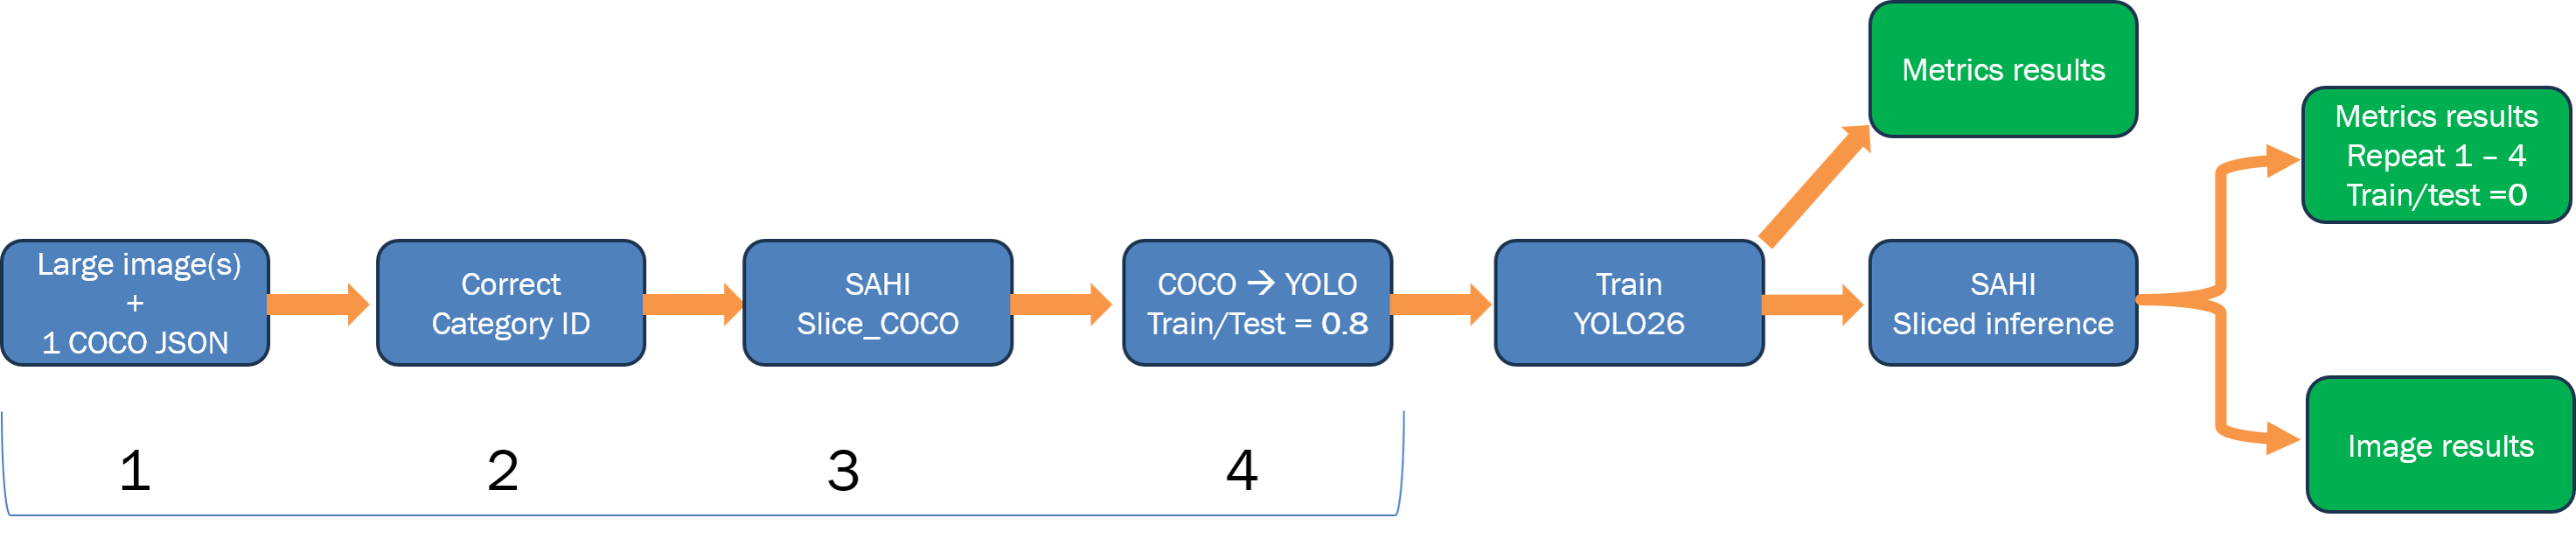

# 2. GPU setup (Colab)

In Google Colab, set **Runtime → Change runtime type → Hardware accelerator → GPU**.

Then verify GPU availability and clear any cached memory.

In [1]:
!nvidia-smi
import torch
torch.cuda.empty_cache()
print("CUDA available:", torch.cuda.is_available())

Wed Oct 14 15:44:45 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  NVIDIA L4                      Off |   00000000:00:03.0 Off |                    0 |
| N/A   44C    P8             13W /   72W |       0MiB /  23034MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

# 3. Install dependencies

We use:
- **SAHI** for slicing large images and COCO annotations.
- **Ultralytics** for YOLOv26 training and inference.
- **gdown** for downloading data from Google Drive.
- **opencv-python** for image I/O and basic visualization.

In [2]:
!pip install -q sahi ultralytics gdown opencv-python

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.9/46.9 kB 1.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 156.3/156.3 kB 1.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 6.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 96.9/96.9 kB 10.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 115.9/115.9 kB 13.1 MB/s eta 0:00:00


# 4. Data annotations

## 4.1 annotation demo

https://roboflow.com/

## 4.2 Download Annotated Dataset

Data credit: **Joshua Konkol and Jeffrey Rollins**.

We download a folder containing:
- One large training image and COCO JSON annotations.
- One large testing image for sliced inference.

In [3]:
import gdown, os

url = "https://drive.google.com/drive/folders/1eIIZVPAQSzX4dnUjOK6j43YKUO1DIcw2?usp=sharing"
gdown.download_folder(url, quiet=False, use_cookies=False)

print("Downloaded files:")
for root, dirs, files in os.walk("data"):
    for f in files:
        print(os.path.join(root, f))

Retrieving folder contents


Retrieving folder 1T2mDXQuU5n4BUgVUuXr8TQ0cCfuRzk_x test_large_images
Processing file 12vaI9GY0e9m1RvCymKTYEx0fSIPqX1OI LauA_-2_2_coco.json
Processing file 1Dmhb6xbeFxX61-ARd7u143OtXIrs7XM7 LauA_-2_2.png
Retrieving folder 1h0DZ-I45E-uWpNaHVYNoJvmrr7lbx4Os train_large
Processing file 1CJS9ETA39l9SU7_m976JanhFdo2sm76p LauC_0_1.json
Processing file 1unudzIO2f4RrHx6e9UrPh6tu_iiOXG_a LauC_0_1.png


Retrieving folder contents completed
Building directory structure
Building directory structure completed
Downloading...
From: https://drive.google.com/uc?id=12vaI9GY0e9m1RvCymKTYEx0fSIPqX1OI
To: /content/data/test_large_images/LauA_-2_2_coco.json
100%|██████████| 1.57M/1.57M [00:00<00:00, 161MB/s]
Downloading...
From (original): https://drive.google.com/uc?id=1Dmhb6xbeFxX61-ARd7u143OtXIrs7XM7
From (redirected): https://drive.google.com/uc?id=1Dmhb6xbeFxX61-ARd7u143OtXIrs7XM7&confirm=t&uuid=d42e7bc4-14d8-43ea-bdc0-a17419365227
To: /content/data/test_large_images/LauA_-2_2.png
100%|██████████| 259M/259M [00:05<00:00, 45.8MB/s]
Downloading...
From: https://drive.google.com/uc?id=1CJS9ETA39l9SU7_m976JanhFdo2sm76p
To: /content/data/train_large/LauC_0_1.json
100%|██████████| 1.57M/1.57M [00:00<00:00, 175MB/s]
Downloading...
From (original): https://drive.google.com/uc?id=1unudzIO2f4RrHx6e9UrPh6tu_iiOXG_a
From (redirected): https://drive.google.com/uc?id=1unudzIO2f4RrHx6e9UrPh6tu_iiOXG_a&conf

Downloaded files:
data/test_large_images/LauA_-2_2.png
data/test_large_images/LauA_-2_2_coco.json
data/train_large/LauC_0_1.png
data/train_large/LauC_0_1.json



Download completed


# 5. SAHI slicing workflow

We will:
1. Fix COCO category IDs (if needed).
2. Slice large images and their COCO annotations into smaller tiles.
3. Visualize sliced annotations.
4. Inspect annotation area distribution and small objects.

This is important because YOLO performs better on reasonably sized objects and images.

In [4]:
import json, os
from sahi.slicing import slice_coco
from sahi.utils.file import load_json
from PIL import Image, ImageDraw
import matplotlib.pyplot as plt

train_large_dir = "/content/data/train_large"
train_json_path = os.path.join(train_large_dir, "LauC_0_1.json")  # JSON name
print("Using COCO JSON:", train_json_path)

Using COCO JSON: /content/data/train_large/LauC_0_1.json


## 5.1 Fix COCO category IDs

In the original notebook, category IDs were large integers (e.g., `1322835112` for vessel, `3724679054` for tylose). We remap them to small integers (0, 1, …) for YOLO.

Adjust `old_category_id` and `new_category_id` as needed for your dataset.

In [5]:
def replace_coco_category_id(input_file, output_file, old_id, new_id):
    """Replace a category ID in a COCO JSON annotation file."""

    with open(input_file, 'r') as f:
        data = json.load(f)

    old_category_found = any(cat['id'] == old_id for cat in data['categories'])
    if not old_category_found:
        print(f"Error: Category with ID {old_id} not found in the input JSON.")
        return

    for category in data['categories']:
        if category['id'] == old_id:
            category['id'] = new_id
            print(f"Updated category ID in 'categories' from {old_id} to {new_id}.")
            break

    annotations_updated_count = 0
    for ann in data['annotations']:
        if ann['category_id'] == old_id:
            ann['category_id'] = new_id
            annotations_updated_count += 1

    print(f"Updated category ID in {annotations_updated_count} annotations.")

    with open(output_file, 'w') as f:
        json.dump(data, f, indent=4)
    print(f"Saved updated JSON to {output_file}.")

# remapping: vessel -> 0
correct_1_path = os.path.join(train_large_dir, "LauC_0_1_correct_1ID.json")
replace_coco_category_id(train_json_path, correct_1_path, old_id=1322835112, new_id=0)

# remapping: tylose -> 1
correct_2_path = os.path.join(train_large_dir, "LauC_0_1_correct_2IDs.json")
replace_coco_category_id(correct_1_path, correct_2_path, old_id=3724679054, new_id=1)



Updated category ID in 'categories' from 1322835112 to 0.
Updated category ID in 3044 annotations.
Saved updated JSON to /content/data/train_large/LauC_0_1_correct_1ID.json.
Updated category ID in 'categories' from 3724679054 to 1.
Updated category ID in 86 annotations.
Saved updated JSON to /content/data/train_large/LauC_0_1_correct_2IDs.json.


## 5.2 Slice large image and COCO JSON

We use SAHI's `slice_coco` to create 640×640 tiles with overlap. This can take several minutes for large images.

Parameters to tune:
- `slice_height`, `slice_width`
- `overlap_height_ratio`, `overlap_width_ratio`
- `min_area_ratio` for keeping partial annotations.

In [6]:
sliced_out_dir = "/content/data/train_sliced_images"
os.makedirs(sliced_out_dir, exist_ok=True)

coco_dict, coco_path = slice_coco(
    coco_annotation_file_path=correct_2_path,
    image_dir=train_large_dir,
    output_coco_annotation_file_name="sliced_LauC01_640x640",
    ignore_negative_samples=True,  # skip empty tile images that contain zero annotations only in JSON, won't delete the empty tile images
    output_dir=sliced_out_dir,
    slice_height=640,
    slice_width=640,
    overlap_height_ratio=0.2,
    overlap_width_ratio=0.2,
    min_area_ratio=0.5,
    verbose=False
)

print("Sliced COCO JSON:", coco_path)
print("Number of sliced images:", len(coco_dict["images"]))
print("Number of annotations:", len(coco_dict["annotations"]))

100%|██████████| 1/1 [04:43<00:00, 283.86s/it]


Sliced COCO JSON: /content/data/train_sliced_images/sliced_LauC01_640x640_coco.json
Number of sliced images: 599
Number of annotations: 4898


## 5.3 Visualize sliced annotations

We plot a grid of sliced images with bounding boxes to visually inspect annotation quality.

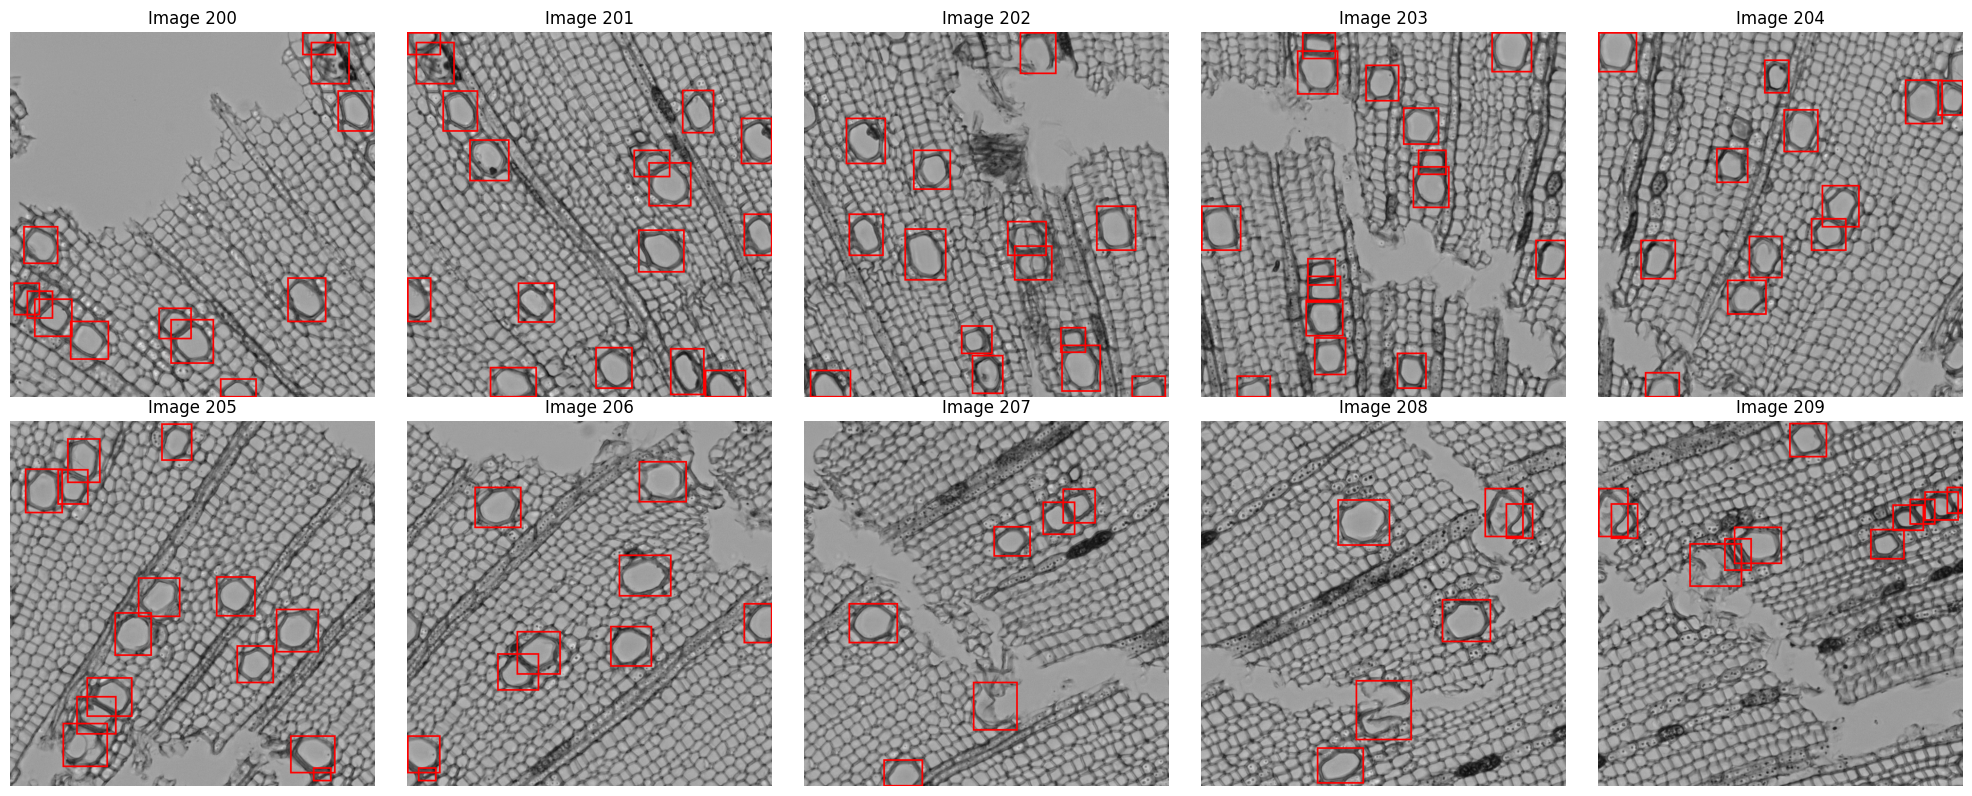

In [8]:
def visualize_slices(coco_dict, coco_json_path, n_rows=2, n_cols=5, start_index=0):
    fig, axes = plt.subplots(n_rows, n_cols, figsize=(4 * n_cols, 4 * n_rows))
    axes = axes.flatten()
    img_dir = os.path.dirname(coco_json_path)

    img_ind = start_index
    for ax in axes:
        if img_ind >= len(coco_dict["images"]):
            ax.axis("off")
            continue
        img_info = coco_dict["images"][img_ind]
        img_path = os.path.join(img_dir, img_info["file_name"])
        img = Image.open(img_path).convert("RGBA")

        for ann in coco_dict["annotations"]:
            if ann["image_id"] == img_info["id"]:
                x, y, w, h = ann["bbox"]
                xyxy = [x, y, x + w, y + h]
                ImageDraw.Draw(img, "RGBA").rectangle(xyxy, outline=(255, 0, 0, 255), width=3)

        ax.imshow(img)
        ax.set_title(f"Image {img_ind}")
        ax.axis("off")
        img_ind += 1

    plt.tight_layout()
    plt.show()

visualize_slices(coco_dict, coco_path, n_rows=2, n_cols=5, start_index=200) # change the start_index as needed

## 5.4 Annotation area distribution

We inspect the distribution of annotation areas to understand object sizes and identify very small objects that may be challenging for YOLO.

Number of annotations: 4898
Max area: 20348 (annotation index: 4692 )


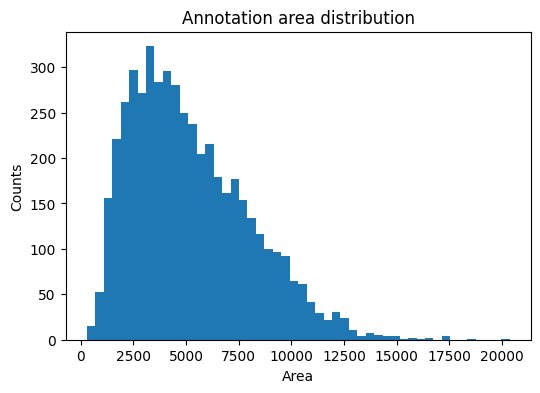

In [9]:
areas = [ann["area"] for ann in coco_dict["annotations"]]
max_area = max(areas)
max_idx = areas.index(max_area)

print("Number of annotations:", len(areas))
print("Max area:", max_area, "(annotation index:", max_idx, ")")

plt.figure(figsize=(6, 4))
plt.hist(areas, bins=50)
plt.ylabel("Counts")
plt.xlabel("Area")
plt.title("Annotation area distribution")
plt.show()

## 5.5 Visualize very small annotations

We identify annotations with area below a threshold (e.g., 700) and visualize them to decide whether they should be kept or filtered.

Number of small annotations: 15


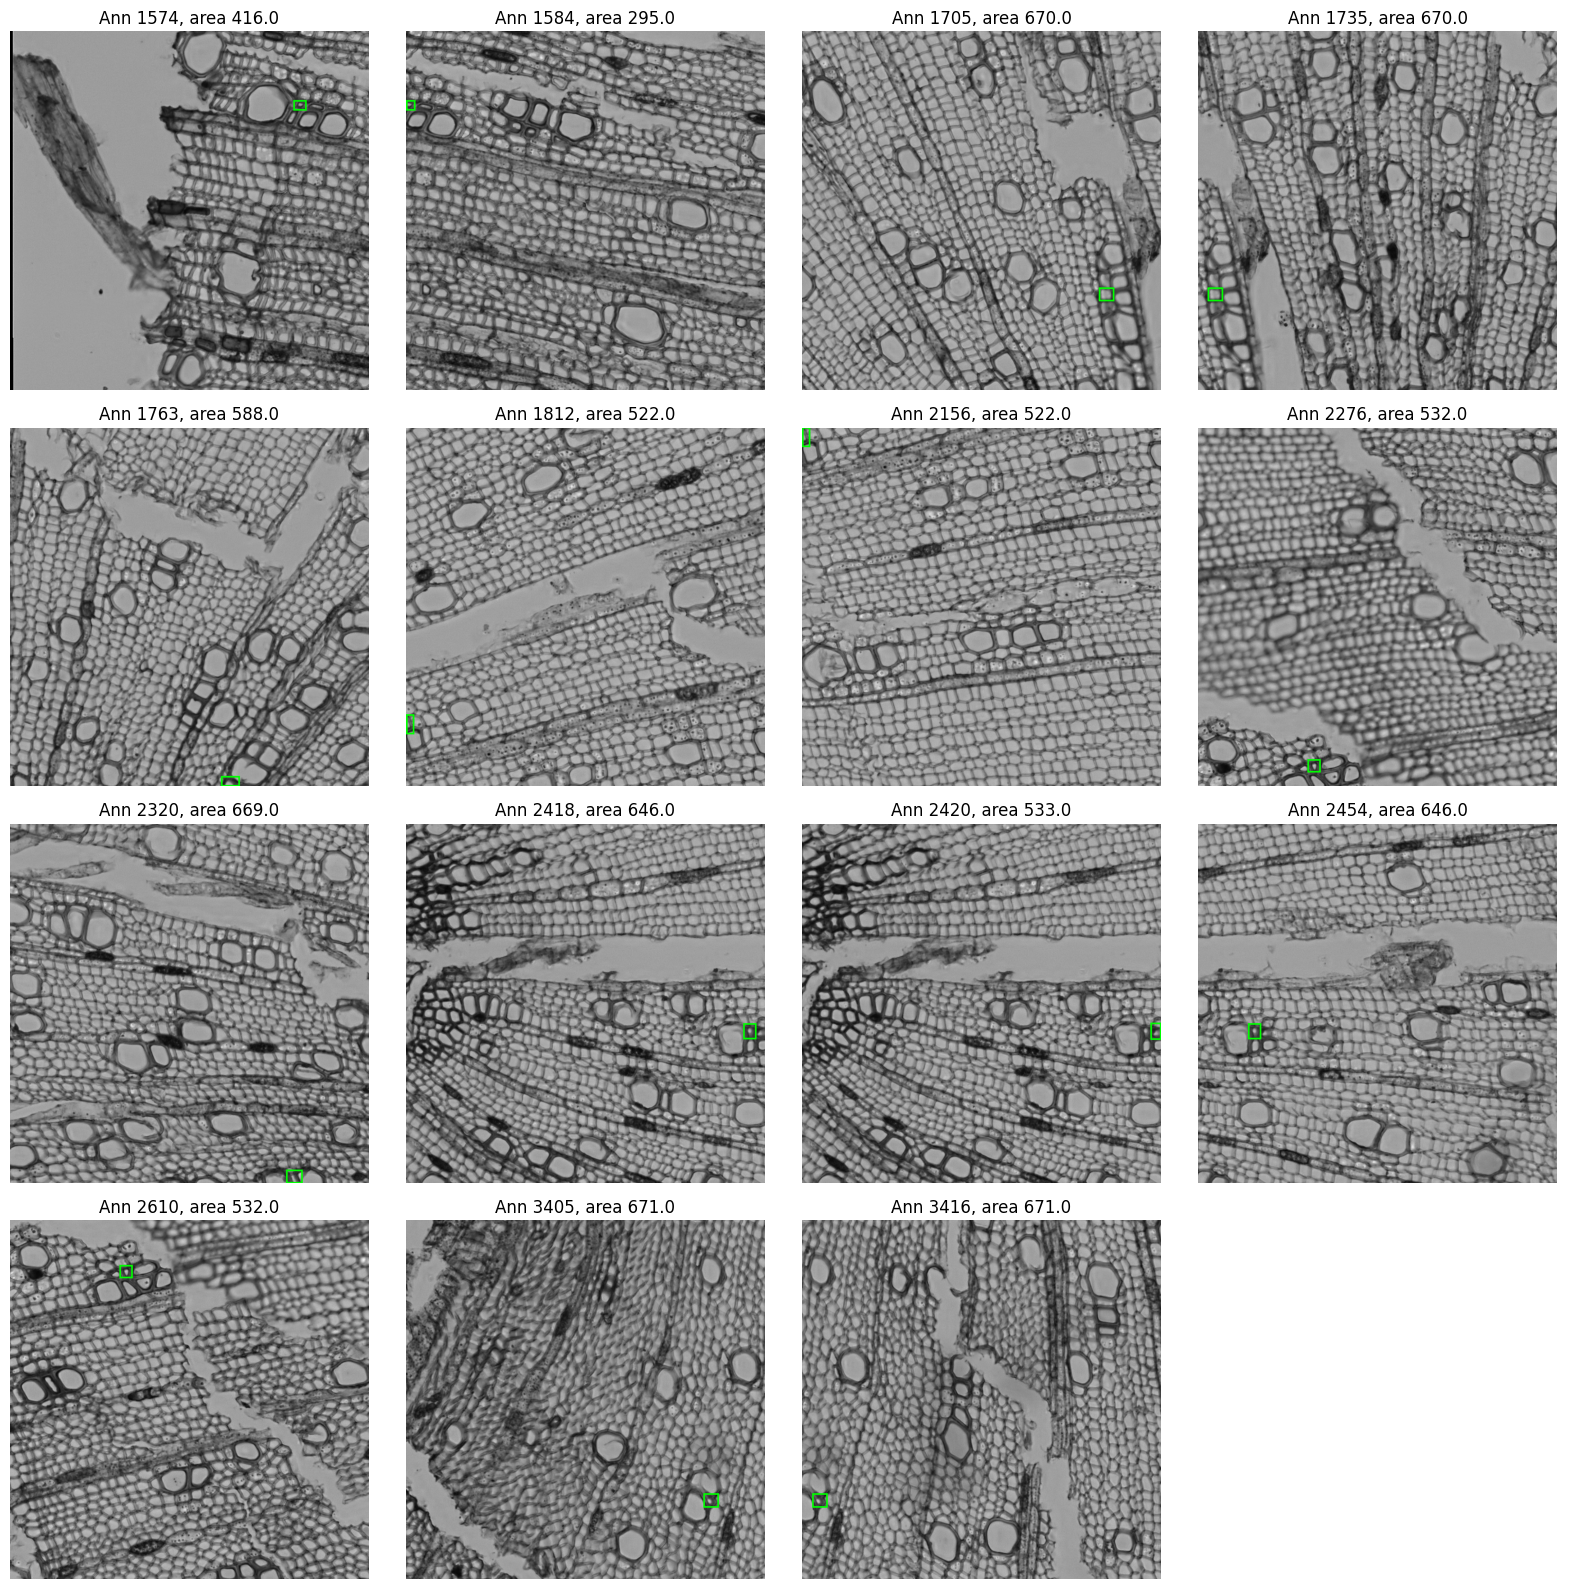

In [10]:
def draw_small_annotations(coco_json_path, area_threshold=700):
    coco_dict = load_json(coco_json_path)
    ann_img_ids = {}
    for ann_id, ann in enumerate(coco_dict["annotations"]):
        if ann["area"] < area_threshold:
            ann_img_ids[ann_id] = ann["image_id"]

    print("Number of small annotations:", len(ann_img_ids))

    if not ann_img_ids:
        return

    n_cols = 4
    n_rows = (len(ann_img_ids) + n_cols - 1) // n_cols
    fig, axes = plt.subplots(n_rows, n_cols, figsize=(4 * n_cols, 4 * n_rows))
    axes = axes.flatten()
    img_dir = os.path.dirname(coco_json_path)

    for ax, (ann_ind, img_id) in zip(axes, ann_img_ids.items()):
        img_idx = img_id - 1
        img_info = coco_dict["images"][img_idx]
        img_path = os.path.join(img_dir, img_info["file_name"])
        img = Image.open(img_path).convert("RGBA")
        xywh = coco_dict["annotations"][ann_ind]["bbox"]
        xyxy = [xywh[0], xywh[1], xywh[0] + xywh[2], xywh[1] + xywh[3]]
        ImageDraw.Draw(img, "RGBA").rectangle(xyxy, outline=(0, 255, 0, 255), width=3)
        ax.imshow(img)
        ax.set_title(f"Ann {ann_ind}, area {coco_dict['annotations'][ann_ind]['area']:.1f}")
        ax.axis("off")

    for ax in axes[len(ann_img_ids):]:
        ax.axis("off")

    plt.tight_layout()
    plt.show()

draw_small_annotations(coco_path, area_threshold=700)

## 5.6 Delete annotations with area < a value

In [11]:
def del_annotions(old_json_path, area_threshold, new_json_path):
    # load old json file
    coco_dict = load_json(old_json_path)

    # pick out the to-be-deleted annotation indexs
    to_be_deleted_ann_inds = []
    for ann_ind in range(len(coco_dict["annotations"])):
        if coco_dict["annotations"][ann_ind]["area"] < area_threshold:
            to_be_deleted_ann_inds.append(ann_ind)

    # sort the indexs reversely, so that delete from the highest index first
    to_be_deleted_ann_inds.sort(reverse=True)
    print(len(to_be_deleted_ann_inds), "indexs to be deleted")

    # delete the items in the annotations list of the coco_dict
    anns_lst = coco_dict["annotations"]
    print(len(anns_lst), "annotations in the old json")
    for i in to_be_deleted_ann_inds:
        del anns_lst[i]

    # update the annotations list of the coco_dict
    coco_dict["annotations"] = anns_lst
    print(len(anns_lst), "annotations in the new json")

    with open(new_json_path, "w") as f:
        json.dump(coco_dict, f, indent=4)

In [12]:
coco_path

'/content/data/train_sliced_images/sliced_LauC01_640x640_coco.json'

In [13]:
# area_threshold = 700

old_json_path = coco_path
new_json_path = "/content/data/train_sliced_images/sliced_LauC01_640x640_coco_gt700.json"
del_annotions(old_json_path, 700, new_json_path)

15 indexs to be deleted
4898 annotations in the old json
4883 annotations in the new json


# 6. Convert sliced COCO to YOLO format

We use SAHI's CLI to convert the sliced COCO annotations to YOLO object detection format.

This will create a directory with `images/`, `labels/`, and a `data.yml` file describing the dataset within the dir: `/content/runs/coco2yolo/`.

In [14]:
coco2yolo_log = !sahi coco yolo --image_dir "/content/data/train_sliced_images" \
                                --dataset_json_path $new_json_path \
                                --train_split 0.9

sliced_yolo_root_path = coco2yolo_log[-1].split("exported to ")[-1].strip()
print("YOLO dataset root:", sliced_yolo_root_path)

data_yaml_path = os.path.join(sliced_yolo_root_path, "data.yml")
print("data.yml path:", data_yaml_path)

assert os.path.exists(data_yaml_path), "data.yml not found!"

YOLO dataset root: runs/coco2yolo/exp
data.yml path: runs/coco2yolo/exp/data.yml


In [15]:
!ls /content/runs${sliced_yolo_root_path}/train/*.png | wc -l

539


In [16]:
!ls /content/runs${sliced_yolo_root_path}/val/*.png | wc -l

60


# 7. Train YOLOv26 object detection

We train a YOLOv26 model (`yolo26n.pt` as a starting point) on the sliced YOLO dataset.

we use reduced epochs (50) for demo. For research, you can use more (e.g., 200).

In [18]:
from ultralytics import YOLO

model = YOLO("yolo26n.pt")  # pretrained YOLO26 weights

project = "yolov26_res_plant_pathology"
name = "50_epochs_demo"

results = model.train(
    data=data_yaml_path,
    device=0,  # use GPU 0
    project=project,
    name=name,
    epochs=50, # adjust as needed
    patience=10,
    batch=32,
    imgsz=640,
    agnostic_nms=True,
    resume=False,
)

Ultralytics 8.4.177 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (NVIDIA L4, 22563MiB)
engine/trainer: agnostic_nms=True, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=32, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=runs/coco2yolo/exp/data.yml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=50, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo26n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=50_epochs_demo, nbs=64, nms=None, opset=None, optimize=False,

# 8. Visualize training metrics

Ultralytics saves training curves (loss, mAP, precision/recall) in the run directory. We display the summary image.

Run directory: /content/runs/detect/yolov26_res_plant_pathology/50_epochs_demo
Results image: /content/runs/detect/yolov26_res_plant_pathology/50_epochs_demo/results.png


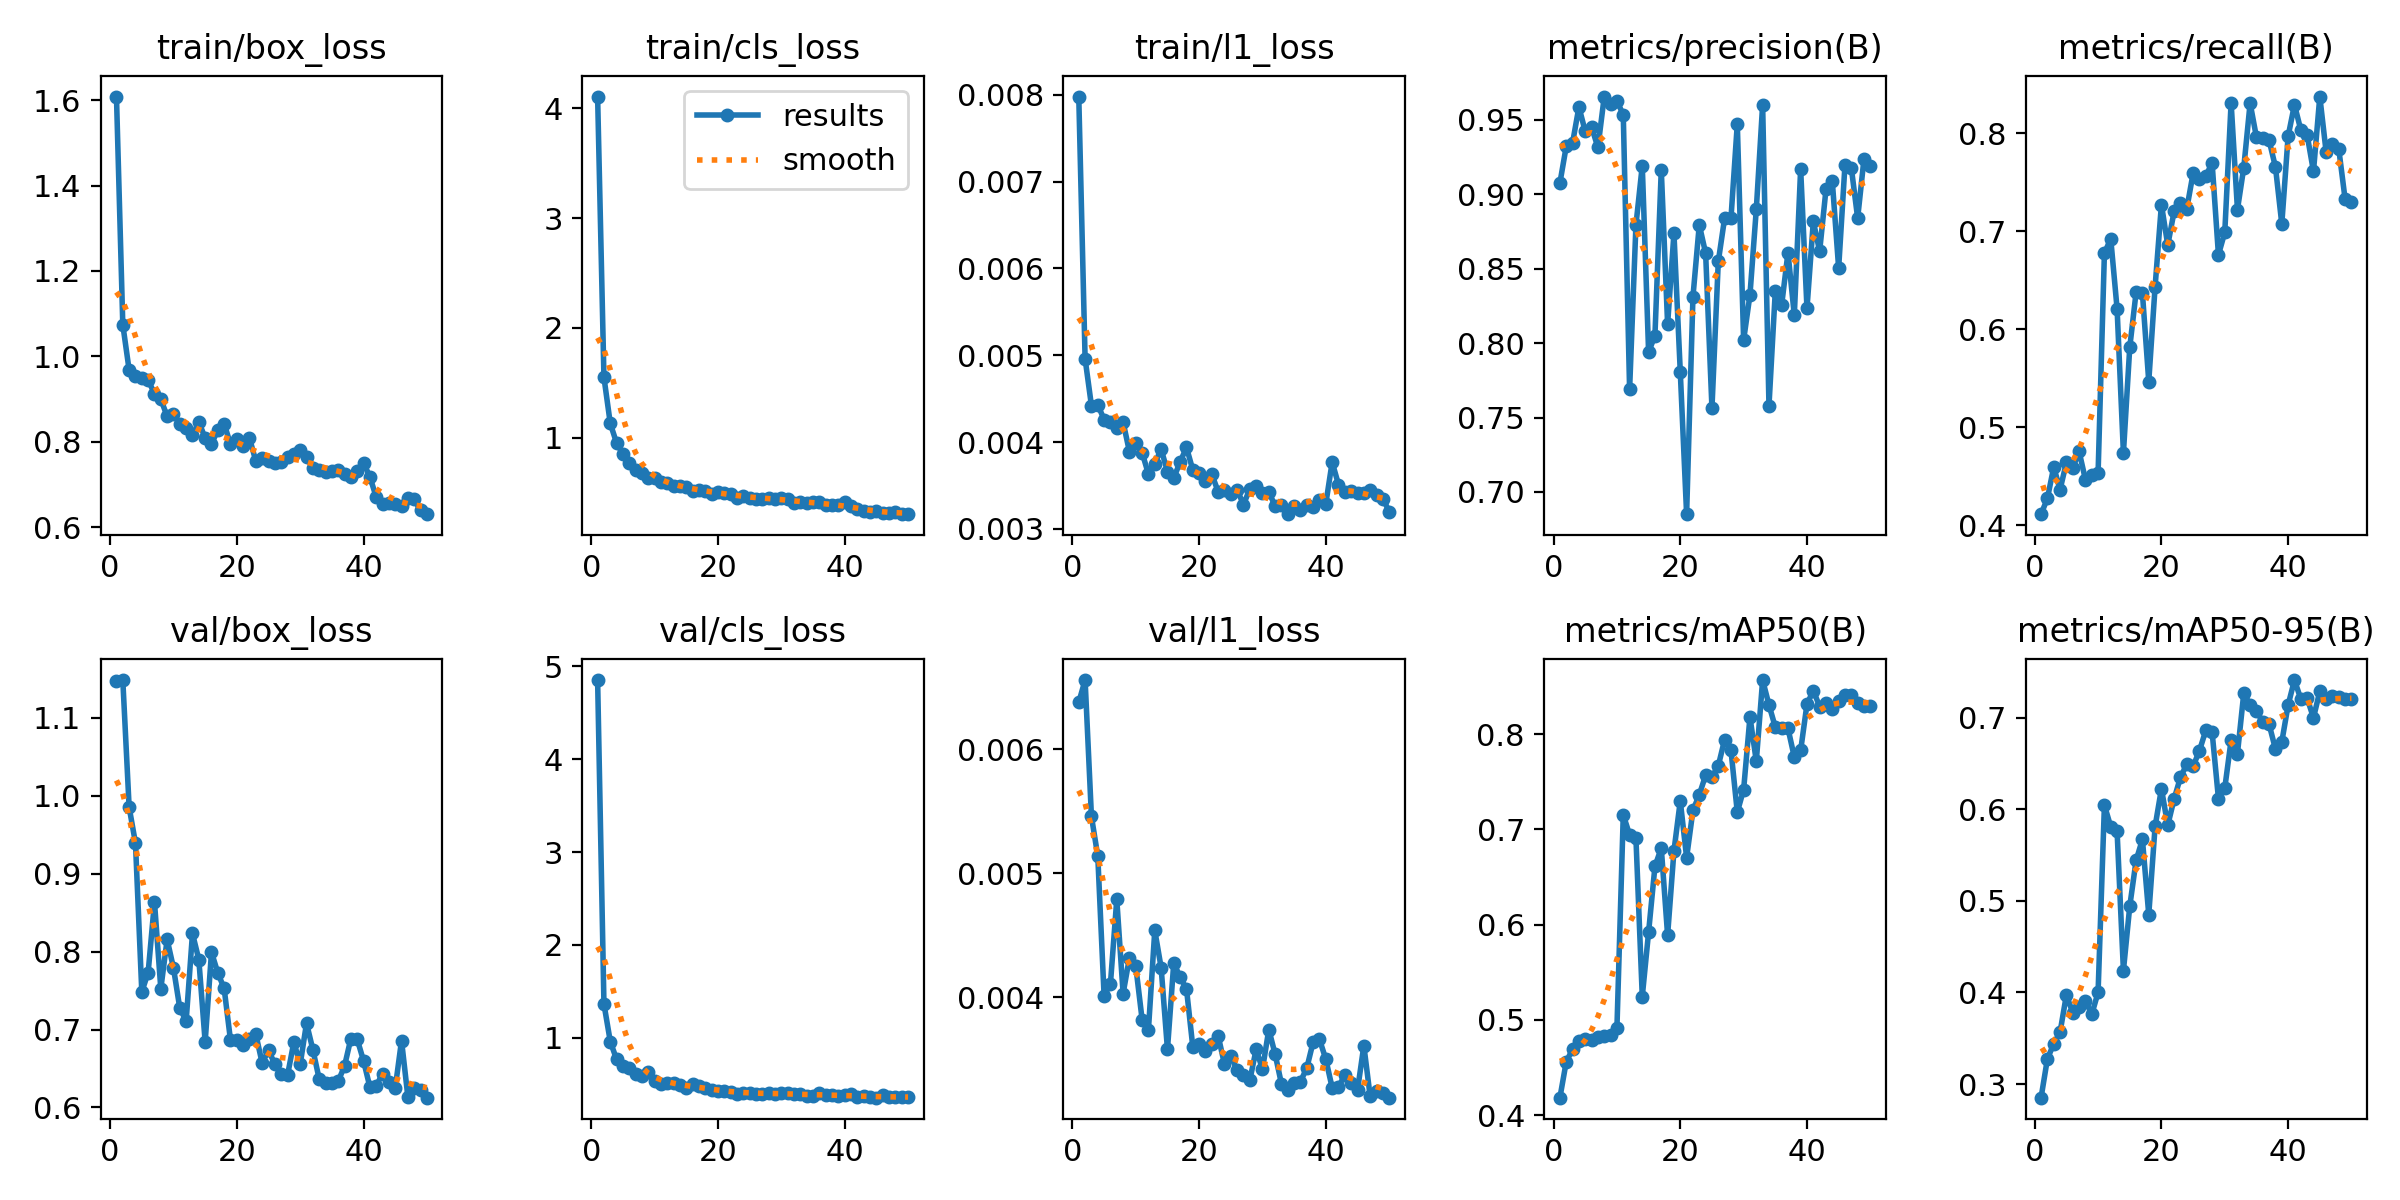

In [19]:
run_dir = "/content/runs/detect/yolov26_res_plant_pathology/50_epochs_demo" # copy from the above output
results_img = os.path.join(run_dir, "results.png")
print("Run directory:", run_dir)
print("Results image:", results_img)

if os.path.exists(results_img):
    display(Image.open(results_img))
else:
    print("Training results image not found. Check your run directory.")

# 9. Evaluate the trained model

We run validation on the dataset defined in `data.yml` to compute metrics such as mAP, precision, and recall.

In [20]:
metrics = model.val(data=data_yaml_path)
# print(metrics)

Ultralytics 8.4.177 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (NVIDIA L4, 22563MiB)
YOLO26n summary (fused): 121 layers, 2,389,978 parameters, 0 gradients, 5.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 4712.1±733.9 MB/s, size: 413.9 KB)
val: Scanning /content/runs/coco2yolo/exp/val.cache... 60 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 60/60 19.4Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 4/4 1.7it/s 2.3s
                   all         60        483      0.812      0.795      0.841      0.739
                vessel         60        469      0.882      0.972      0.982      0.842
                tylose         11         14      0.742      0.618      0.699      0.637
Speed: 3.7ms preprocess, 10.5ms inference, 0.0ms loss, 5.5ms postprocess per image
Results saved to /content/runs/detect/val


evaluate unseen large image via slicing

In [21]:
# remapping: vessel -> 0
test_json_path = "/content/data/test_large_images/LauA_-2_2_coco.json"
correct_test1_path = "/content/data/test_large_images/LauA_-2_2_correct_1ID.json"
replace_coco_category_id(test_json_path, correct_test1_path, old_id=1322835112, new_id=0)

# remapping: tylose -> 1
correct_test2_path = "/content/data/test_large_images/LauA_-2_2_correct_2IDs.json"
replace_coco_category_id(correct_test1_path, correct_test2_path, old_id=3724679054, new_id=1)

coco_dict, coco_path = slice_coco(
    coco_annotation_file_path=correct_test2_path,
    image_dir="/content/data/test_large_images",
    output_coco_annotation_file_name="sliced_LauA22_640x640",
    ignore_negative_samples=True,  # skip empty tile images that contain zero annotations only in JSON, won't delete the empty tile images
    output_dir="/content/data/test_sliced_images",
    slice_height=640,
    slice_width=640,
    overlap_height_ratio=0.2,
    overlap_width_ratio=0.2,
    min_area_ratio=0.5,
    verbose=False
)

Updated category ID in 'categories' from 1322835112 to 0.
Updated category ID in 3028 annotations.
Saved updated JSON to /content/data/test_large_images/LauA_-2_2_correct_1ID.json.
Updated category ID in 'categories' from 3724679054 to 1.
Updated category ID in 96 annotations.
Saved updated JSON to /content/data/test_large_images/LauA_-2_2_correct_2IDs.json.


100%|██████████| 1/1 [05:06<00:00, 306.78s/it]


In [22]:
!sahi coco yolo --image_dir "/content/data/test_sliced_images" \
                --dataset_json_path "/content/data/test_sliced_images/sliced_LauA22_640x640_coco.json" \
                --train_split 0 # all images sent to valid folder

Loading coco annotations: 100% 650/650 [00:00<00:00, 1363.87it/s]
2026-10-14 16:32:52,257 - sahi - INFO - generating image symlinks and annotation files for yolo... (coco.py:1600)
100% 650/650 [00:00<00:00, 1058.56it/s]
COCO to YOLO conversion results are successfully exported to runs/coco2yolo/exp2


In [23]:
metrics2 = model.val(data="/content/runs/coco2yolo/exp2/data.yml")

Ultralytics 8.4.177 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (NVIDIA L4, 22563MiB)
YOLO26n summary (fused): 121 layers, 2,389,978 parameters, 0 gradients, 5.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 4298.2±844.6 MB/s, size: 417.9 KB)
val: Scanning /content/runs/coco2yolo/exp2/val... 650 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 650/650 1.1Kit/s 0.6s
val: New cache created: /content/runs/coco2yolo/exp2/val.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 41/41 6.9it/s 5.9s
                   all        650       4939       0.64      0.629      0.637       0.52
                vessel        647       4768      0.887      0.861       0.92      0.765
                tylose        103        171      0.393      0.398      0.354      0.275
Speed: 0.9ms preprocess, 1.9ms inference, 0.0ms loss, 1.3ms postprocess per image
Results saved to /content/runs/detect/val-2


# 10. Sliced inference on large test images

We now apply the trained YOLOv26 model to large test images using SAHI sliced inference.

This allows us to detect objects across the full resolution of large microscopy or imaging data.

## 10.1 get_sliced_prediction() single prediction

In [24]:
from sahi import AutoDetectionModel
from sahi.predict import get_sliced_prediction

# 1. Properly initialize the SAHI DetectionModel wrapper
model = AutoDetectionModel.from_pretrained(
    model_type="ultralytics",          # Use "ultralytics" for YOLOv8/YOLOv11/YOLO26
    model_path=f"/content/runs/detect/{project}/{name}/weights/best.pt", # Path to your weights file (e.g., 'yolov8n.pt')
    confidence_threshold=0.25,          # Set your confidence threshold here
    device="cuda:0",                    # Use "cuda:0" for GPU or "cpu"
)

# Define directory containing large test images
test_large_dir = "/content/data/test_large_images"

# Gather all valid image paths from the directory
test_images = [
    os.path.join(test_large_dir, f)
    for f in os.listdir(test_large_dir)
    if f.lower().endswith((".png", ".jpg", ".jpeg", ".tif", ".tiff"))
]

print("Test images:", test_images)

# Loop through each image and run SAHI sliced inference
for img_path in test_images:
    print("\nSliced inference on:", img_path)

    # Perform sliced prediction
    result = get_sliced_prediction(
        img_path,
        model,
        postprocess_class_agnostic=True,
        slice_height=640,
        slice_width=640,
        overlap_height_ratio=0.2,
        overlap_width_ratio=0.2,
    )

    # Export the visual predictions to the output directory
    output_dir = "sliced_inference_results_gsp"
    file_name = os.path.basename(img_path)
    result.export_visuals(export_dir=output_dir,
                          text_size=0.5,  # Adjust text/label size (default is usually larger; try values like 0.5 to 1.0)
                          rect_th=2,  # Thickness of bounding box lines
                          file_name=file_name)

    # Check if the visualization was saved successfully
    vis_path = os.path.join(output_dir, file_name)
    if os.path.exists(vis_path):
        print(f"Visual results successfully saved to: {vis_path}")


Test images: ['/content/data/test_large_images/LauA_-2_2.png']

Sliced inference on: /content/data/test_large_images/LauA_-2_2.png
Performing prediction on 900 slices.


## 10.2 batch predicting

In [25]:
from sahi import AutoDetectionModel
from sahi.predict import predict

model_path=f"/content/runs/detect/{project}/{name}/weights/best.pt"
model_config_path = f"/content/runs/detect/{project}/{name}/args.yaml"  # agnostic_nms=True in this file
images_dir = "/content/data/test_large_images"


predict( # predict() has nothing to return
    model_type='ultralytics', # one of 'ultralytics', 'mmdet', 'huggingface'
    model_path=model_path,
    model_config_path=model_config_path,
    postprocess_class_agnostic=True,
    no_standard_prediction=True,
    no_sliced_prediction=False,
    model_device="cuda:0", # "cpu" or 'cuda:0'
    model_confidence_threshold=0.25,
    source=images_dir,
    slice_height=640,
    slice_width=640,
    overlap_height_ratio=0.2,
    overlap_width_ratio=0.2,
    visual_bbox_thickness=1,
    visual_text_size=0.5,
    visual_text_thickness=1,
    export_pickle=True
)

There are 1 listed files in folder: test_large_images/


Performing inference on images:   0%|          | 0/1 [00:04<?, ?it/s]

Performing prediction on 900 slices.


Performing inference on images:   0%|          | 0/1 [00:20<?, ?it/s]

Prediction time is: 15297.16 ms


Performing inference on images: 100%|██████████| 1/1 [00:31<00:00, 31.63s/it]

Prediction results are successfully exported to runs/predict/exp


# 11. Export detection results

We can export detection results to CSV for downstream analysis (e.g., tylose counts).

### from gsp()

In [32]:
import pandas as pd

def detections_to_dataframe(result):
    rows = []
    for det in result.object_prediction_list:
        bbox = det.bbox.to_xyxy()
        rows.append({
            "class_name": det.category.name,
            "score": det.score.value,
            "x1": bbox[0],
            "y1": bbox[1],
            "x2": bbox[2],
            "y2": bbox[3],
        })
    return pd.DataFrame(rows)

df = detections_to_dataframe(result)
csv_path = "detections_example_gsp.csv"
df.to_csv(csv_path, index=False)
print("Saved detections to:", csv_path)

df.head()

Saved detections to: detections_example_gsp.csv


,class_name,score,x1,y1,x2,y2
0,vessel,0.933514,4620.767174,10628.210999,4723.265625,10741.650696
1,vessel,0.932244,5535.512512,10565.269287,5636.748535,10676.681702
2,vessel,0.930557,4096.751831,6892.632095,4216.507690,6998.603638
3,vessel,0.929649,8612.149292,13458.470642,8704.499268,13576.389557
4,vessel,0.928609,8638.557312,3603.156570,8734.999817,3720.496185


In [27]:
df[df.class_name == "tylose"]

,class_name,score,x1,y1,x2,y2
1705,tylose,0.857933,7316.654663,7586.375000,7403.921783,7662.244812
1725,tylose,0.856695,11725.766846,12432.401306,11831.755222,12530.427795
1774,tylose,0.853201,4636.016357,8208.203247,4687.854004,8272.718628
1798,tylose,0.849990,10976.304779,13398.908104,11046.551117,13481.465668
1804,tylose,0.849521,12180.841248,12694.706909,12283.431458,12798.186890
...,...,...,...,...,...,...
2830,tylose,0.281124,7699.035706,10081.073853,7742.716614,10140.263550
2831,tylose,0.280610,5349.350220,5126.617073,5427.298401,5190.862946
2838,tylose,0.277060,11290.484497,12065.240326,11369.019897,12137.098175
2860,tylose,0.256617,6900.274658,6684.614410,6989.246277,6755.129692


### from predict()

In [28]:
import pickle

In [29]:
def pred_results_to_dataframe(pickle_file_path):
    # Load the data from the pickle file
    with open(pickle_file_path, 'rb') as f:
        object_prediction_list = pickle.load(f)

    rows = []

    for det in object_prediction_list:
            bbox = det.bbox.to_xyxy()
            rows.append({
                "class_name": det.category.name,
                "score": det.score.value,
                "x1": bbox[0],
                "y1": bbox[1],
                "x2": bbox[2],
                "y2": bbox[3],
            })

    return pd.DataFrame(rows)

In [30]:
pickle_file_path = "/content/runs/predict/exp/pickles/LauA_-2_2.pickle"
df2 = pred_results_to_dataframe(pickle_file_path)
csv_path = "detections_example2.csv"
df2.to_csv(csv_path, index=False)
print("Saved detections to:", csv_path)

df2.head()

Saved detections to: detections_example.csv


,class_name,score,x1,y1,x2,y2
0,vessel,0.933514,4620.767174,10628.210999,4723.265625,10741.650696
1,vessel,0.932244,5535.512512,10565.269287,5636.748535,10676.681702
2,vessel,0.930557,4096.751831,6892.632095,4216.507690,6998.603638
3,vessel,0.929649,8612.149292,13458.470642,8704.499268,13576.389557
4,vessel,0.928609,8638.557312,3603.156570,8734.999817,3720.496185


In [31]:
df2[df2.class_name == "tylose"]

,class_name,score,x1,y1,x2,y2
1705,tylose,0.857933,7316.654663,7586.375000,7403.921783,7662.244812
1725,tylose,0.856695,11725.766846,12432.401306,11831.755222,12530.427795
1774,tylose,0.853201,4636.016357,8208.203247,4687.854004,8272.718628
1798,tylose,0.849990,10976.304779,13398.908104,11046.551117,13481.465668
1804,tylose,0.849521,12180.841248,12694.706909,12283.431458,12798.186890
...,...,...,...,...,...,...
2830,tylose,0.281124,7699.035706,10081.073853,7742.716614,10140.263550
2831,tylose,0.280610,5349.350220,5126.617073,5427.298401,5190.862946
2838,tylose,0.277060,11290.484497,12065.240326,11369.019897,12137.098175
2860,tylose,0.256617,6900.274658,6684.614410,6989.246277,6755.129692


# 12. Summary

In this notebook, you:
- Used SAHI to slice large images and COCO annotations.
- Converted COCO JSON annotations to YOLO format.
- Trained and evaluated a YOLO26 object detection model.
- Performed sliced inference on large test images.
- Exported detection results for downstream analysis.

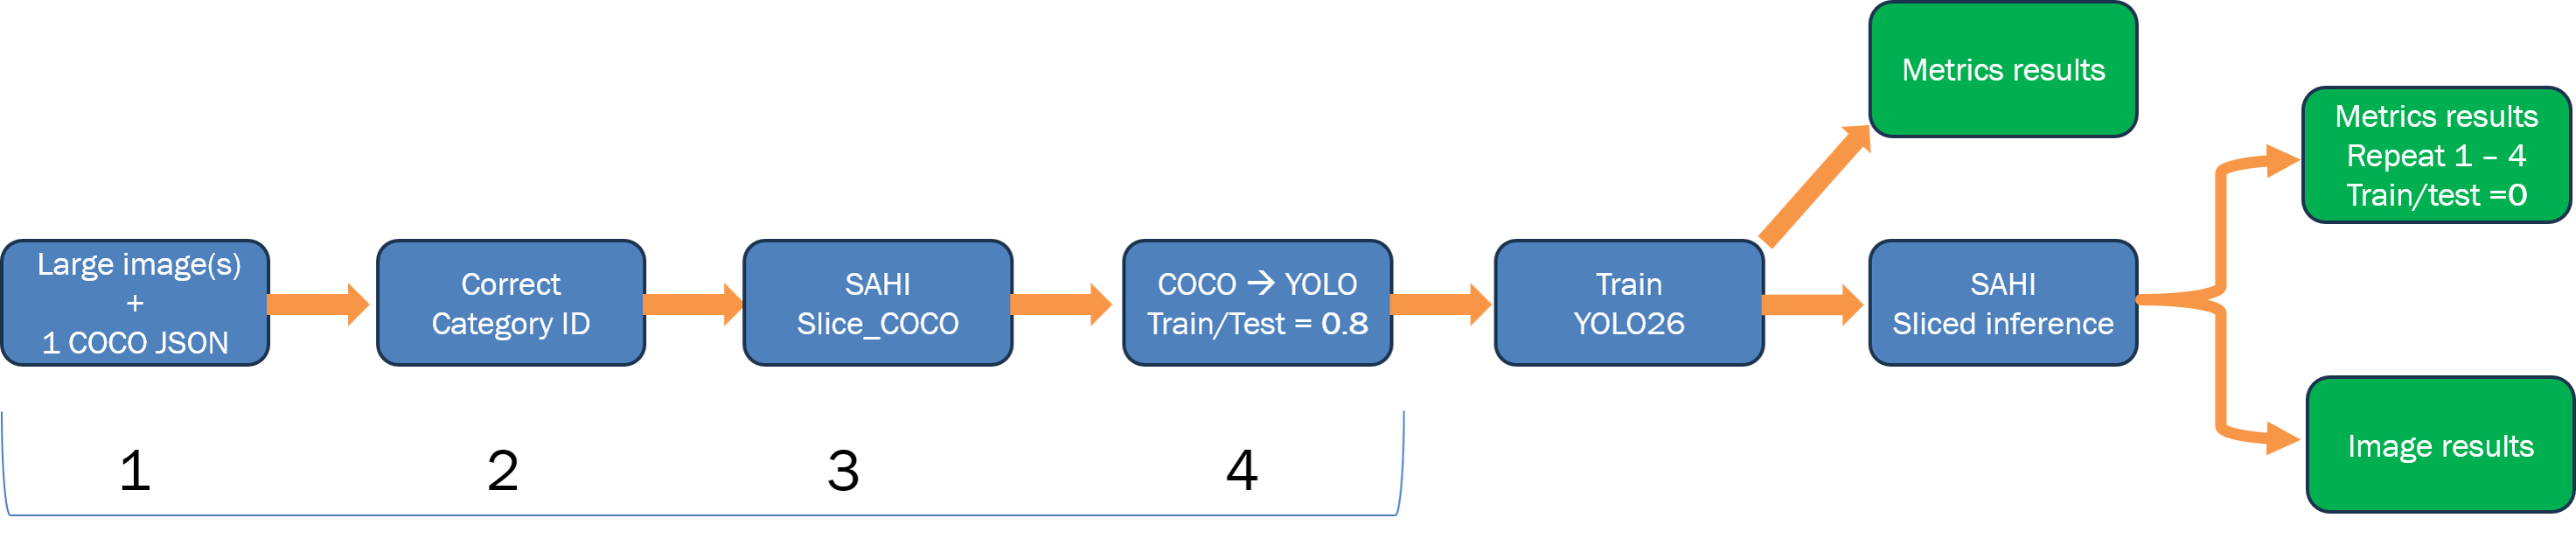
This workflow can be adapted to other plant‑pathology datasets and scaled to HPC environments for larger experiments.